DEA

In [1]:
import pandas as pd
import pulp
import matplotlib.pyplot as plt

In [3]:
# Load CSV file
file_path = r"C:\Users\levyg\OneDrive\Desktop\Levy\Mestrado\Disciplinas Mestrado\Dissertação\DADOS testes AWS.csv"
df = pd.read_csv(file_path, sep=';')

In [4]:
df

,Config (DMUs),Qtde. V.Ms (WorldPress),Users,%95 (ms),Custo,Carga de falha
0,1 Locust t3.small - 1 DB t3.small ...,2,50,8100,0.08,50
1,1 Locust t3.small - 1 DB t3.small ...,3,50,6400,0.10,50
2,1 Locust t3.medium - 1 DB t3.medium - 2 VM ...,2,50,8200,0.17,50
3,1 Locust t3.large - 1 DB t3.large ...,3,50,3600,0.42,100
4,1 Locust t3.large - 1 DB t3.medium - 4...,4,50,3800,0.46,100
5,1 Locust t3.large - 1 DB t3.medium - 2...,2,50,2300,0.46,125


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Config (DMUs)            6 non-null      object 
 1   Qtde. V.Ms (WorldPress)  6 non-null      int64  
 2   Users                    6 non-null      int64  
 3   %95 (ms)                 6 non-null      int64  
 4   Custo                    6 non-null      float64
 5   Carga de falha           6 non-null      int64  
dtypes: float64(1), int64(4), object(1)
memory usage: 420.0+ bytes


In [8]:
# Define DMUs, inputs, and outputs
DMUs = df['Config (DMUs)'].tolist()
inputs = df[['Qtde. V.Ms (WorldPress)',  'Custo']].values
outputs = df[['Users', '%95 (ms)', 'Carga de falha']].values


CRS

In [9]:
# Function to perform DEA CRS
def dea_crs(inputs, outputs, DMUs):
    num_dmus = len(DMUs)
    num_inputs = inputs.shape[1]
    num_outputs = outputs.shape[1]
    
    results = []
    
    for dmu in range(num_dmus):
        # Create the problem
        prob = pulp.LpProblem(f"DEA_CRS_DMU_{DMUs[dmu]}", pulp.LpMaximize)
        
        # Define decision variables (weights for inputs and outputs)
        u = pulp.LpVariable.dicts("u", range(num_outputs), lowBound=0)
        v = pulp.LpVariable.dicts("v", range(num_inputs), lowBound=0)
        
        # Objective function: maximize the efficiency of the DMU
        prob += pulp.lpSum([u[j] * outputs[dmu][j] for j in range(num_outputs)])
        
        # Constraints: efficiency of all DMUs should be <= 1
        for i in range(num_dmus):
            prob += pulp.lpSum([u[j] * outputs[i][j] for j in range(num_outputs)]) - \
                    pulp.lpSum([v[k] * inputs[i][k] for k in range(num_inputs)]) <= 0
        
        # Normalization constraint: sum of input weights = 1
        prob += pulp.lpSum([v[k] * inputs[dmu][k] for k in range(num_inputs)]) == 1
        
        # Solve the problem
        prob.solve()
        
        # Extract results
        efficiency = pulp.value(prob.objective)
        u_values = [pulp.value(u[j]) for j in range(num_outputs)]
        v_values = [pulp.value(v[k]) for k in range(num_inputs)]
        
        # Calculate weighted inputs and outputs
        weighted_inputs = sum([v_values[k] * inputs[dmu][k] for k in range(num_inputs)])
        weighted_outputs = sum([u_values[j] * outputs[dmu][j] for j in range(num_outputs)])
        
        results.append({
            'DMU': DMUs[dmu],
            'Qtd': inputs[dmu][0],
            'Custo total': inputs[dmu][1],
            'Lucro Bruto': outputs[dmu][0],
            'weight_Qtd': v_values[0],
            'weight_Custo_total': v_values[1],
            'weight_Lucro_Bruto': u_values[0],
            'inputs_weighted': weighted_inputs,
            'outputs_weighted': weighted_outputs,
            'efficiency': efficiency
        })
    
    # Convert results to DataFrame
    df_crs = pd.DataFrame(results)
    
    # Add ranking column (1 = most efficient, higher numbers = less efficient)
    df_crs['Ranking'] = df_crs['efficiency'].rank(ascending=False, method='min').astype(int)
    
    # Sort by ranking (most efficient to least efficient)
    df_crs = df_crs.sort_values(by='Ranking').reset_index(drop=True)
    
    return df_crs

# Run DEA CRS
df_crs = dea_crs(inputs, outputs, DMUs)

# Save results to CSV
df_crs.to_csv('dea_crs_results.csv', index=False)

print("DEA CRS Results with Ranking:")
df_crs

C:\Users\levyg\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pulp\pulp.py:1298: UserWarning: Spaces are not permitted in the name. Converted to '_'
  warnings.warn("Spaces are not permitted in the name. Converted to '_'")


DEA CRS Results with Ranking:


,DMU,Qtd,Custo total,Lucro Bruto,weight_Qtd,weight_Custo_total,weight_Lucro_Bruto,inputs_weighted,outputs_weighted,efficiency,Ranking
0,1 Locust t3.medium - 1 DB t3.medium - 2 VM ...,2.0,0.17,50,0.500000,0.000000,0.0,1.0,1.000000,1.000000,1
1,1 Locust t3.large - 1 DB t3.medium - 2...,2.0,0.46,50,0.500000,0.000000,0.0,1.0,1.000000,1.000000,2
2,1 Locust t3.small - 1 DB t3.small ...,2.0,0.08,50,0.494513,0.137174,0.0,1.0,1.000000,1.000000,3
3,1 Locust t3.small - 1 DB t3.small ...,3.0,0.10,50,0.000000,10.000000,0.0,1.0,0.800000,0.800000,4
4,1 Locust t3.large - 1 DB t3.large ...,3.0,0.42,50,0.127451,1.470588,0.0,1.0,0.745098,0.745098,5
5,1 Locust t3.large - 1 DB t3.medium - 4...,4.0,0.46,50,0.107438,1.239669,0.0,1.0,0.628099,0.628099,6


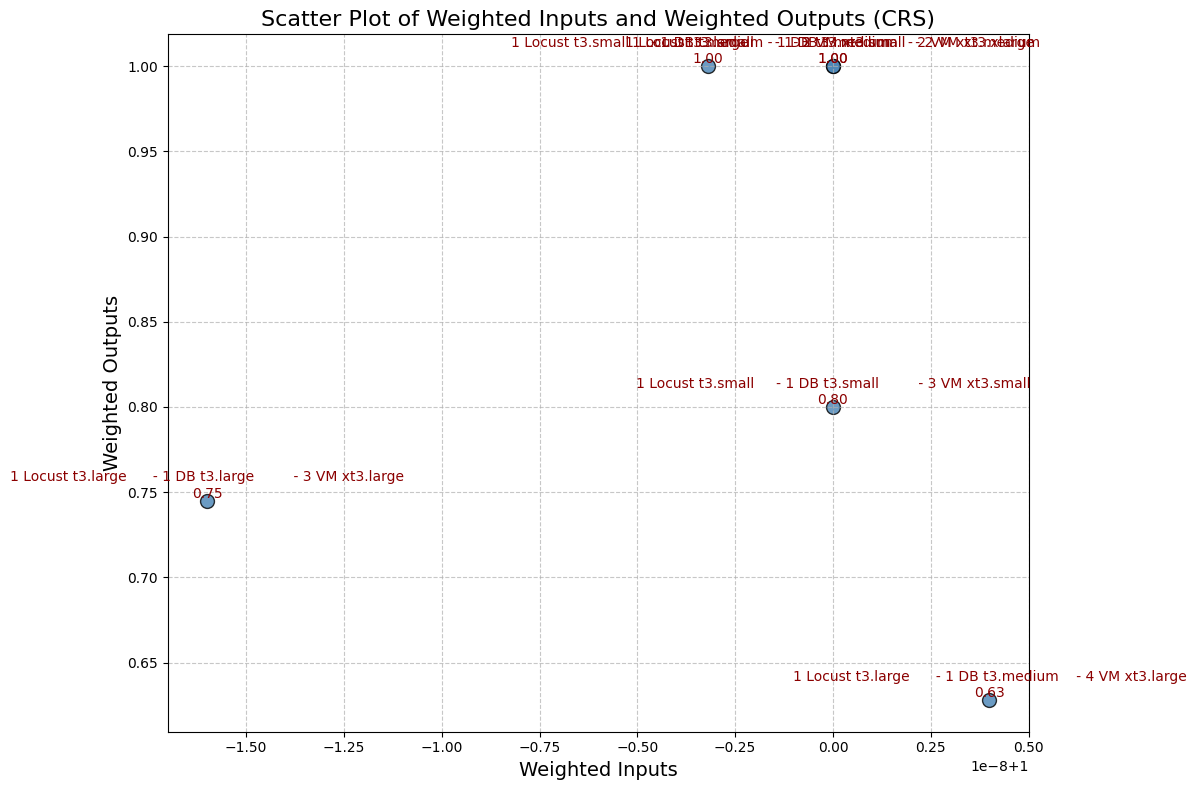

In [10]:
# Plot the scatter plot
plt.figure(figsize=(12, 8))

# Create the scatter plot
plt.scatter(
    df_crs['inputs_weighted'],  # Weighted Inputs on the X-axis
    df_crs['outputs_weighted'],  # Weighted Outputs on the Y-axis
    s=100,  # Size of the points
    alpha=0.8,  # Transparency of the points
    color='steelblue',  # Color of the points
    edgecolors='k'  # Outline of the points
)

# Add data labels (DMU and Efficiency)
for i in range(len(df_crs)):
    dmu = df_crs['DMU'].iloc[i]
    eficiencia = df_crs['efficiency'].iloc[i]
    x = df_crs['inputs_weighted'].iloc[i]
    y = df_crs['outputs_weighted'].iloc[i]
    plt.text(
        x, y, 
        f'{dmu}\n{eficiencia:.2f}', 
        fontsize=10, ha='center', va='bottom', color='darkred'
    )

# Add labels and title
plt.title('Scatter Plot of Weighted Inputs and Weighted Outputs (CRS)', fontsize=16)
plt.xlabel('Weighted Inputs', fontsize=14)
plt.ylabel('Weighted Outputs', fontsize=14)

# Adjust grid for better visualization
plt.grid(True, linestyle='--', alpha=0.7)

# Display the plot
plt.tight_layout()
plt.show()

VRS

In [11]:
# Function to perform DEA VRS
def dea_vrs(inputs, outputs, DMUs):
    num_dmus = len(DMUs)
    num_inputs = inputs.shape[1]
    num_outputs = outputs.shape[1]
    
    results = []
    
    for dmu in range(num_dmus):
        # Create the problem
        prob = pulp.LpProblem(f"DEA_VRS_DMU_{DMUs[dmu]}", pulp.LpMaximize)
        
        # Define decision variables (weights for inputs and outputs)
        u = pulp.LpVariable.dicts("u", range(num_outputs), lowBound=0)
        v = pulp.LpVariable.dicts("v", range(num_inputs), lowBound=0)
        u0 = pulp.LpVariable("u0", cat='Continuous')  # Free variable for VRS
        
        # Objective function: maximize the efficiency of the DMU
        prob += pulp.lpSum([u[j] * outputs[dmu][j] for j in range(num_outputs)]) + u0
        
        # Constraints: efficiency of all DMUs should be <= 1
        for i in range(num_dmus):
            prob += pulp.lpSum([u[j] * outputs[i][j] for j in range(num_outputs)]) - \
                    pulp.lpSum([v[k] * inputs[i][k] for k in range(num_inputs)]) + u0 <= 0
        
        # Normalization constraint: sum of input weights = 1
        prob += pulp.lpSum([v[k] * inputs[dmu][k] for k in range(num_inputs)]) == 1
        
        # Solve the problem
        prob.solve()
        
        # Extract results
        efficiency = pulp.value(prob.objective)
        u_values = [pulp.value(u[j]) for j in range(num_outputs)]
        v_values = [pulp.value(v[k]) for k in range(num_inputs)]
        u0_value = pulp.value(u0)
        
        # Calculate weighted inputs and outputs
        weighted_inputs = sum([v_values[k] * inputs[dmu][k] for k in range(num_inputs)])
        weighted_outputs = sum([u_values[j] * outputs[dmu][j] for j in range(num_outputs)]) + u0_value
        
        results.append({
            'DMU': DMUs[dmu],
            'Qtd': inputs[dmu][0],
            'Custo total': inputs[dmu][1],
            'Lucro Bruto': outputs[dmu][0],
            'weight_Qtd': v_values[0],
            'weight_Custo_total': v_values[1],
            'weight_Lucro_Bruto': u_values[0],
            'inputs_weighted': weighted_inputs,
            'outputs_weighted': weighted_outputs,
            'efficiency': efficiency
        })
    
    # Convert results to DataFrame
    df_vrs = pd.DataFrame(results)
    
    # Add ranking column (1 = most efficient, higher numbers = less efficient)
    df_vrs['Ranking'] = df_vrs['efficiency'].rank(ascending=False, method='min').astype(int)
    
    # Sort by ranking (most efficient to least efficient)
    df_vrs = df_vrs.sort_values(by='Ranking').reset_index(drop=True)
    
    return df_vrs

# Run DEA VRS
df_vrs = dea_vrs(inputs, outputs, DMUs)

# Save results to CSV
df_vrs.to_csv('dea_vrs_results.csv', index=False)

print("DEA VRS Results with Ranking:")
df_vrs

C:\Users\levyg\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pulp\pulp.py:1298: UserWarning: Spaces are not permitted in the name. Converted to '_'
  warnings.warn("Spaces are not permitted in the name. Converted to '_'")


DEA VRS Results with Ranking:


,DMU,Qtd,Custo total,Lucro Bruto,weight_Qtd,weight_Custo_total,weight_Lucro_Bruto,inputs_weighted,outputs_weighted,efficiency,Ranking
0,1 Locust t3.medium - 1 DB t3.medium - 2 VM ...,2.0,0.17,50,0.5,0.000000e+00,0.0,1.0,1.000000,1.000000,1
1,1 Locust t3.small - 1 DB t3.small ...,2.0,0.08,50,0.5,7.782454e-11,0.0,1.0,1.000000,1.000000,2
2,1 Locust t3.large - 1 DB t3.medium - 2...,2.0,0.46,50,0.5,0.000000e+00,0.0,1.0,1.000000,1.000000,2
3,1 Locust t3.small - 1 DB t3.small ...,3.0,0.10,50,0.0,1.000000e+01,0.0,1.0,0.800000,0.800000,4
4,1 Locust t3.large - 1 DB t3.large ...,3.0,0.42,50,0.0,2.380952e+00,0.0,1.0,0.793651,0.793651,5
5,1 Locust t3.large - 1 DB t3.medium - 4...,4.0,0.46,50,0.0,2.173913e+00,0.0,1.0,0.724638,0.724638,6


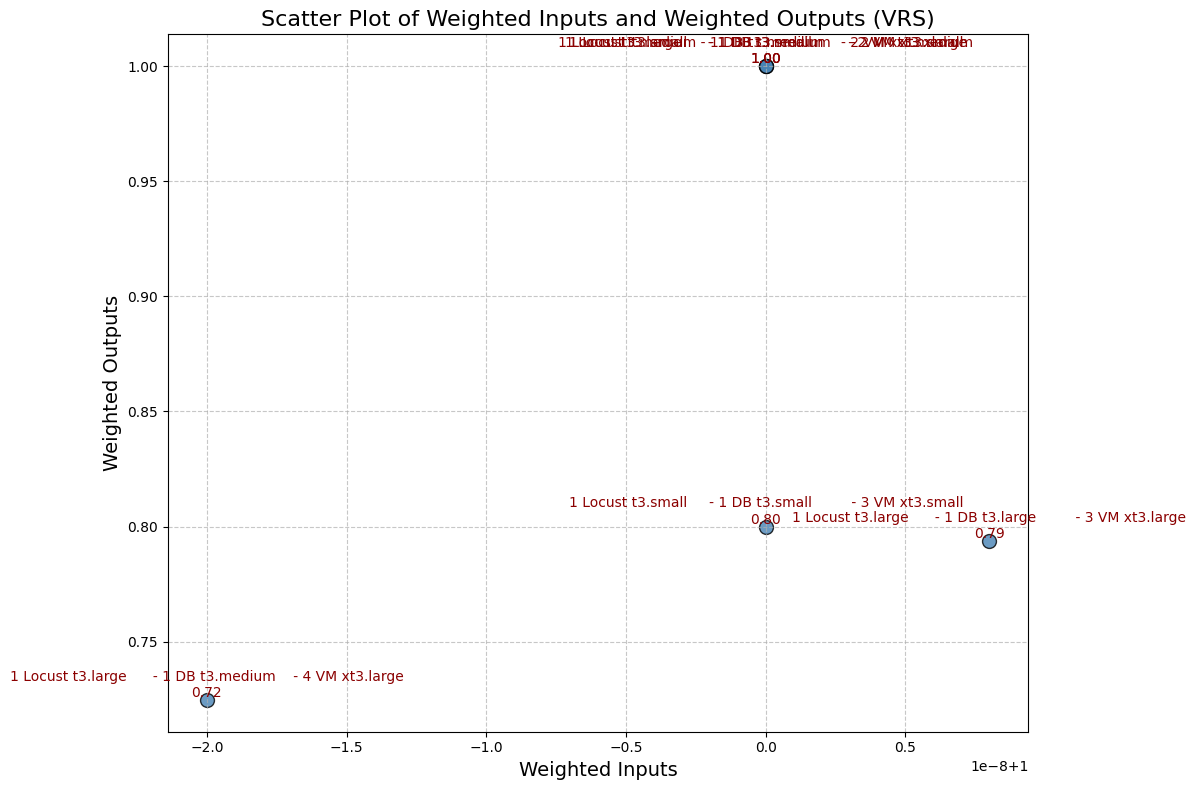

In [12]:
# Plot the scatter plot
plt.figure(figsize=(12, 8))

# Create the scatter plot
plt.scatter(
    df_vrs['inputs_weighted'],  # Weighted Inputs on the X-axis
    df_vrs['outputs_weighted'],  # Weighted Outputs on the Y-axis
    s=100,  # Size of the points
    alpha=0.8,  # Transparency of the points
    color='steelblue',  # Color of the points
    edgecolors='k'  # Outline of the points
)

# Add data labels (DMU and Efficiency)
for i in range(len(df_vrs)):
    dmu = df_vrs['DMU'].iloc[i]
    eficiencia = df_vrs['efficiency'].iloc[i]
    x = df_vrs['inputs_weighted'].iloc[i]
    y = df_vrs['outputs_weighted'].iloc[i]
    plt.text(
        x, y, 
        f'{dmu}\n{eficiencia:.2f}', 
        fontsize=10, ha='center', va='bottom', color='darkred'
    )

# Add labels and title
plt.title('Scatter Plot of Weighted Inputs and Weighted Outputs (VRS)', fontsize=16)
plt.xlabel('Weighted Inputs', fontsize=14)
plt.ylabel('Weighted Outputs', fontsize=14)

# Adjust grid for better visualization
plt.grid(True, linestyle='--', alpha=0.7)

# Display the plot
plt.tight_layout()
plt.show()